# Few shot 예시 선택

**이 노트북에서 할 일**

1. 02절 과업 명세 목록에, 다른 고객 문의와 그 답으로 된 예시 한 쌍을 더합니다.
2. 예시 없음·관련 예시·관련 없는 예시 세 목록을 같은 모델로 보내, 답 원문·토큰 수·줄 수를 비교합니다.
3. 예시 답의 줄바꿈만 ` / `로 바꿔, 예시 모양과 형식 지시가 어긋날 때 답이 어떻게 되는지 봅니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없습니다.

인터넷 서비스에 요청을 모두 4번 보냅니다. 모두 `gpt-5.4-mini`입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

**강의와 실습 범위** — 강의 시간에는 3~7절(예시 만들기와 붙이기, 세 목록 보내기, 기록표와 답 모양)을 설명합니다.
8·9절(확인 단어와 예시 낱말, 값 바꿔 보기)은 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.10.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch07-prompt-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

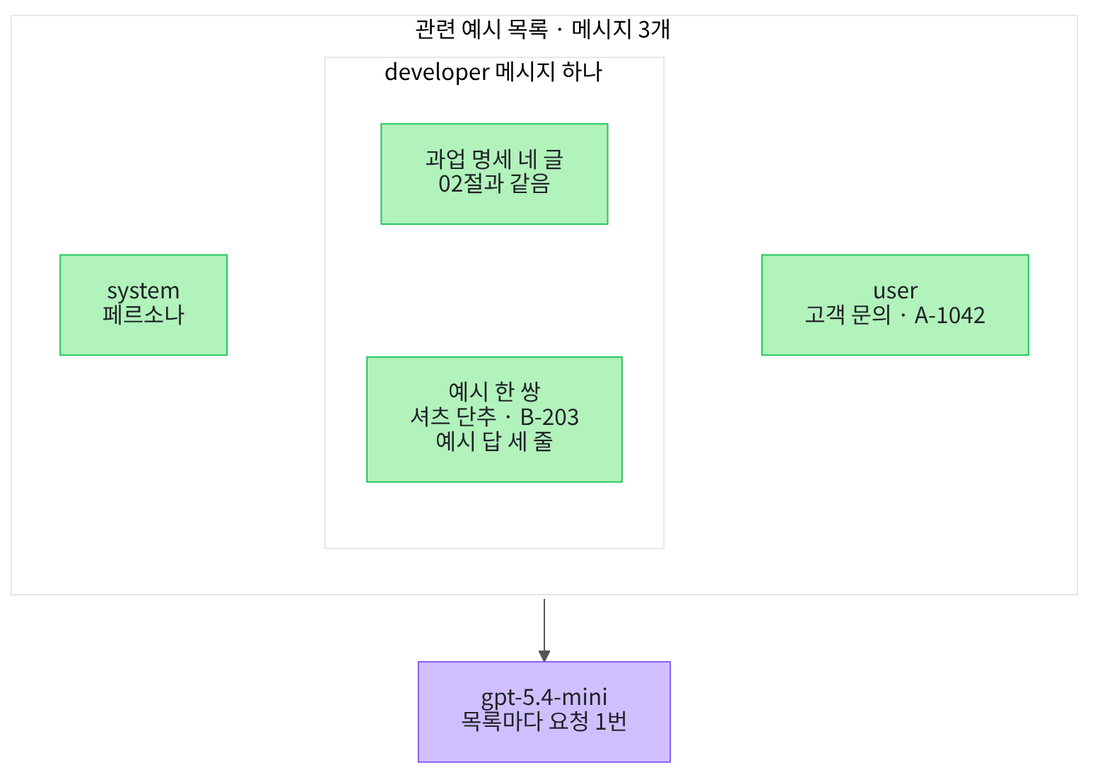

위에서 아래로 읽습니다. 큰 칸은 이 노트북의 관련 예시 목록이고, 메시지는 02절과 같은 세 개입니다.
가운데 developer 메시지 칸 안에서 02절 과업 명세 뒤에 예시 한 쌍이 붙습니다.
예시 없음 목록은 이 칸에 과업 명세만 있고, 관련 없는 예시 목록은 예시 자리에 다른 주제의 예시가 들어갑니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01·02절과 같은 실습 폴더와 같은 판입니다. 노트북은 앞 절 없이 새 커널에서 시작하므로 다시 확인합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.10.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `langchain-openai: 1.6.0` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

모델 객체를 만드는 함수를 불러오고, 앞에서 배운 기록 함수 두 개를 가져옵니다.

앞에서 배운 함수는 `llm_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 Ch 6 06절 `timed_invoke()`와 01절 `make_prompt_record()`를 가져옵니다.

In [2]:
# 모델 객체를 만드는 함수를 불러옵니다
from langchain.chat_models import init_chat_model
# Ch 6 06절·01절 기록 함수 두 개를 도구 파일에서 가져옵니다
from llm_tools import make_prompt_record, timed_invoke

01·02절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01·02절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다. 실행마다 답 문장이 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 2. 02절 과업 명세 다시 만들기

이 절은 02절의 과업 명세 목록에 예시만 더합니다. 그래서 02절의 글을 글자까지 같게 다시 만듭니다.
페르소나 글, 고객 문의, 과업 명세 네 글(목표·필수 정보·금지 사항·출력 형식)입니다.
네 글은 02절처럼 줄바꿈 `"\n"`으로 이어 과업 명세 글 하나로 만듭니다.

In [5]:
# 02절과 같은 페르소나 글·고객 문의·과업 명세 네 글을 만들고, 네 글을 줄바꿈으로 잇습니다
persona_text = "당신은 친절한 고객 상담원입니다."
inquiry_text = "어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다."
goal_text = "고객 문의를 분류하고 필요한 다음 행동을 안내하세요."
required_text = "회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요."
forbidden_text = "근거 없는 보상은 약속하지 마세요."
format_text = "분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요."
task_text = goal_text + "\n" + required_text + "\n" + forbidden_text + "\n" + format_text
print("페르소나:", persona_text)
print("고객 문의:", inquiry_text)
print("과업 명세:")
print(task_text)

페르소나: 당신은 친절한 고객 상담원입니다.
고객 문의: 어제 받은 텀블러 뚜껑이 깨졌습니다. 주문번호는 A-1042입니다. 새 상품으로 바꾸고 싶습니다.
과업 명세:
고객 문의를 분류하고 필요한 다음 행동을 안내하세요.
회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요.
근거 없는 보상은 약속하지 마세요.
분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.


**결과 읽기** — 첫 두 줄은 `페르소나: 당신은 친절한 고객 상담원입니다.`와 `고객 문의:`로 시작하는 줄입니다.
라벨 줄 `과업 명세:` 아래 네 줄이 과업 명세 글이고, 마지막 줄은 `분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.`입니다.
세 글 모두 02절과 같은 글자입니다.

## 3. 예시 한 쌍 만들기

예시(example)는 다른 고객 문의 하나와, 그 문의에 알맞은 답 하나를 짝지은 글입니다.
처음 쓰는 서류 옆에 붙은 작성 견본 한 장과 비슷합니다. 규칙 설명 대신 채운 모양을 보여 줍니다.
예시는 요청 글에 함께 실어 보내는 글일 뿐, 모델을 다시 학습시키지 않습니다.
예시 없이 지시만 주는 방식을 Zero-shot, 예시 몇 개를 함께 주는 방식을 Few-shot이라고 부릅니다.

예시 글은 이 노트북에서 세 번 만듭니다. 같은 모양으로 만들려고 함수 `make_example_text()`를 정의합니다.
예시 문의와 예시 답을 받아, 「예시 문의:」 줄과 「예시 답:」 줄을 붙인 글 하나를 반환합니다.
이 셀은 함수를 정의만 하므로 출력이 없습니다.

In [6]:
# 예시 문의와 예시 답을 받아, 두 이름표 줄을 붙인 예시 글 하나를 반환하는 함수를 정의합니다
def make_example_text(example_inquiry, example_answer):
    example_text = "예시 문의: " + example_inquiry + "\n" + "예시 답:" + "\n" + example_answer
    return example_text

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

첫째 예시는 관련 예시입니다. 셔츠 단추가 떨어진 문의라서, 상품에 하자가 있어 교환하려는 점이 텀블러 문의와 같습니다.
예시 답은 02절 출력 형식대로 분류·다음 행동·고객 문장 세 줄로 씁니다.
주문번호는 일부러 현재 문의의 `A-1042`와 다른 `B-203`을 씁니다. 예시의 값이 새 답에 섞이는지 나중에 확인하려는 것입니다.

글을 세 번에 나눠 `+`로 이어 붙이는 것은 긴 줄을 읽기 좋게 나누려는 것입니다.

In [7]:
# 같은 종류의 다른 문의(셔츠 단추·B-203)와 세 줄 답으로 관련 예시를 만듭니다
relevant_inquiry = "셔츠 단추가 떨어졌습니다. 주문번호는 B-203입니다."
relevant_answer = "분류: 교환 요청(하자)\n"
relevant_answer = relevant_answer + "다음 행동: 떨어진 단추 사진을 받고 주문번호 B-203으로 교환 접수를 진행합니다.\n"
relevant_answer = relevant_answer + "고객에게 보낼 한 문장: 단추가 떨어진 부분의 사진을 보내 주시면 교환 접수를 도와드리겠습니다."
relevant_example = make_example_text(relevant_inquiry, relevant_answer)
print("관련 예시:")
print(relevant_example)

관련 예시:
예시 문의: 셔츠 단추가 떨어졌습니다. 주문번호는 B-203입니다.
예시 답:
분류: 교환 요청(하자)
다음 행동: 떨어진 단추 사진을 받고 주문번호 B-203으로 교환 접수를 진행합니다.
고객에게 보낼 한 문장: 단추가 떨어진 부분의 사진을 보내 주시면 교환 접수를 도와드리겠습니다.


**결과 읽기** — 라벨 줄 `관련 예시:` 아래 첫 줄은 `예시 문의: 셔츠 단추가 떨어졌습니다. 주문번호는 B-203입니다.`입니다.
그 아래 `예시 답:` 줄이 있고, 세 줄 답이 `분류: 교환 요청(하자)`부터 이어집니다.

둘째 예시는 관련 없는 예시입니다. 뉴스레터 글꼴을 바꾸고 싶다는 문의라서, 파손·사진·교환과 관계가 없습니다.
답 모양은 관련 예시와 같은 세 줄로 맞춥니다. 두 예시의 차이를 주제 하나로 좁히려는 것입니다.

In [8]:
# 답 모양(세 줄)은 같고 주제가 다른 문의(뉴스레터 글꼴)로 관련 없는 예시를 만듭니다
unrelated_inquiry = "뉴스레터 글꼴을 바꾸고 싶습니다."
unrelated_answer = "분류: 설정 문의\n"
unrelated_answer = unrelated_answer + "다음 행동: 계정 설정 메뉴의 글꼴 항목 위치를 안내합니다.\n"
unrelated_answer = unrelated_answer + "고객에게 보낼 한 문장: 계정 설정 메뉴의 글꼴 항목에서 원하는 글꼴을 고르실 수 있습니다."
unrelated_example = make_example_text(unrelated_inquiry, unrelated_answer)
print("관련 없는 예시:")
print(unrelated_example)

관련 없는 예시:
예시 문의: 뉴스레터 글꼴을 바꾸고 싶습니다.
예시 답:
분류: 설정 문의
다음 행동: 계정 설정 메뉴의 글꼴 항목 위치를 안내합니다.
고객에게 보낼 한 문장: 계정 설정 메뉴의 글꼴 항목에서 원하는 글꼴을 고르실 수 있습니다.


**결과 읽기** — 라벨 줄 `관련 없는 예시:` 아래 첫 줄은 `예시 문의: 뉴스레터 글꼴을 바꾸고 싶습니다.`입니다.
세 줄 답은 `분류: 설정 문의`부터 이어집니다. 사진·주문번호·교환이라는 낱말은 없습니다.

## 4. 예시를 developer 글에 붙이기

예시는 developer 메시지 안, 과업 명세 뒤에 붙입니다. OpenAI 프롬프트 안내서는 예시를 보통 developer 메시지의 한 부분으로 넣는다고 설명합니다.
글 `"\n\n"`은 줄바꿈 두 번이라, 과업 명세와 예시 사이에 빈 줄 하나가 생깁니다.
실행 전에 예상합니다. 과업 명세 네 줄, 빈 줄 하나, 예시 다섯 줄이라 줄 수는 10일 것입니다.

In [9]:
# 과업 명세 뒤에 빈 줄 하나를 두고 예시를 붙여 developer 글 두 개를 만듭니다(요청은 보내지 않습니다)
relevant_developer = task_text + "\n\n" + relevant_example
unrelated_developer = task_text + "\n\n" + unrelated_example
relevant_developer_lines = relevant_developer.split("\n")
print("관련 예시를 더한 developer 글:")
print(relevant_developer)
print("줄 수(빈 줄 포함):", len(relevant_developer_lines))

관련 예시를 더한 developer 글:
고객 문의를 분류하고 필요한 다음 행동을 안내하세요.
회사 규정상 교환 접수에는 파손 사진이 필요합니다. 주문번호는 답에 그대로 적으세요.
근거 없는 보상은 약속하지 마세요.
분류, 다음 행동, 고객에게 보낼 한 문장을 한 줄씩 세 줄로 답하세요.

예시 문의: 셔츠 단추가 떨어졌습니다. 주문번호는 B-203입니다.
예시 답:
분류: 교환 요청(하자)
다음 행동: 떨어진 단추 사진을 받고 주문번호 B-203으로 교환 접수를 진행합니다.
고객에게 보낼 한 문장: 단추가 떨어진 부분의 사진을 보내 주시면 교환 접수를 도와드리겠습니다.
줄 수(빈 줄 포함): 10


**결과 읽기** — 라벨 줄 아래 처음 네 줄은 과업 명세이고, 그다음 빈 줄 하나 뒤에 `예시 문의:` 줄이 있습니다.
마지막 줄은 `줄 수(빈 줄 포함): 10`입니다. 예상과 같습니다.

이제 세 목록을 만듭니다. system에는 페르소나, user에는 고객 문의를 둡니다. developer 글만 조건마다 다릅니다.
예시 없음 목록은 02절 과업 명세 목록과 같은 목록입니다.
세 목록의 system·user 메시지는 같아야 하므로 연산자 `and`로 두 비교를 묶어 `assert`로 확인합니다.

In [10]:
# 세 목록을 만들고 system·user 메시지가 모두 같은지 확인합니다(요청은 보내지 않습니다)
zero_messages = [("system", persona_text), ("developer", task_text), ("user", inquiry_text)]
relevant_messages = [("system", persona_text), ("developer", relevant_developer), ("user", inquiry_text)]
unrelated_messages = [("system", persona_text), ("developer", unrelated_developer), ("user", inquiry_text)]
same_system = zero_messages[0] == relevant_messages[0] and zero_messages[0] == unrelated_messages[0]
same_user = zero_messages[2] == relevant_messages[2] and zero_messages[2] == unrelated_messages[2]
print("세 목록의 system 메시지가 같은가:", same_system)
print("세 목록의 user 메시지가 같은가:", same_user)
assert same_system
assert same_user

세 목록의 system 메시지가 같은가: True
세 목록의 user 메시지가 같은가: True


**결과 읽기** — 두 줄은 `세 목록의 system 메시지가 같은가: True`와 `세 목록의 user 메시지가 같은가: True`입니다. `assert`도 통과했습니다.
세 목록은 developer 글 뒤쪽의 예시만 다릅니다.

## 5. 세 목록을 같은 모델로 보내기

준비 셀에서 가져온 함수 두 개로 요청마다 기록 한 줄을 만듭니다. 함수 `timed_invoke()`는 요청을 보내면서 걸린 시간을 재고, 응답 객체와 걸린 초를 튜플로 반환합니다.
함수 `make_prompt_record()`는 조건 이름·응답 객체·걸린 초로 딕셔너리 한 줄을 만듭니다.
키는 `조건`·`답`·`입력 토큰 수`·`출력 토큰 수`·`끝난 이유`·`걸린 초` 여섯 개입니다.

예시 없음 목록을 먼저 보냅니다. 02절 과업 명세 목록과 같은 목록이라 비교의 기준이 됩니다.
실행 전에 예상합니다. 02절처럼 세 줄 답에 주문번호와 사진 요청이 있을 것입니다. 글자까지 같을까요?

In [11]:
# 예시 없음 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
zero_response, zero_elapsed = timed_invoke(model, zero_messages)
zero_record = make_prompt_record("예시 없음", zero_response, zero_elapsed)
print("답:")
print(zero_record["답"])

답:
분류: 파손 교환 문의  
다음 행동: 교환 접수를 위해 파손된 뚜껑 사진을 보내주세요. 주문번호 A-1042 확인했습니다.  
고객에게 보낼 한 문장: 파손 사진을 보내주시면 주문번호 A-1042 기준으로 교환 가능 여부를 확인해 안내드리겠습니다.


**결과 읽기** — 라벨 줄 아래 세 줄은 `분류: 파손 교환 문의`, `다음 행동:`, `고객에게 보낼 한 문장:`으로 시작합니다.
다음 행동 줄에 `주문번호 A-1042 확인했습니다.`가 있고, 두 줄에 사진 요청이 있습니다. 보상 약속은 없었습니다.

02절에서 같은 목록을 보냈을 때도 첫 줄은 같았지만, 다음 행동 줄의 끝맺음은 달랐습니다. 교재를 만들 때 앞선 새 커널 실행에서는 이 답의 첫 줄이 「분류: 교환 요청(파손)」이었습니다.
목록이 같아도 실행마다 낱말이 달라집니다. 그래서 이 절은 02절 답이 아니라, 이 노트북에서 방금 받은 예시 없음 답을 기준으로 비교합니다.

이번에는 관련 예시 목록을 보냅니다. 바꾼 것은 넘기는 목록 하나입니다.
실행 전에 예상합니다. 답이 예시 답의 낱말과 문장 모양을 따라 할까요? 예시의 `B-203`이 섞일까요?

In [12]:
# 관련 예시 목록을 같은 모델로 보내고 기록 한 줄을 만듭니다(요청 1번)
relevant_response, relevant_elapsed = timed_invoke(model, relevant_messages)
relevant_record = make_prompt_record("관련 예시", relevant_response, relevant_elapsed)
print("답:")
print(relevant_record["답"])

답:
분류: 교환 요청(파손)
다음 행동: 파손 사진을 받아 주문번호 A-1042로 교환 접수를 진행합니다.
고객에게 보낼 한 문장: 뚜껑이 깨진 부분의 사진을 보내 주시면 주문번호 A-1042로 교환 접수를 도와드리겠습니다.


**결과 읽기** — 라벨 줄 아래 세 줄은 `분류: 교환 요청(파손)`, `다음 행동:`, `고객에게 보낼 한 문장:`으로 시작합니다.
다음 행동 줄은 `다음 행동: 파손 사진을 받아 주문번호 A-1042로 교환 접수를 진행합니다.`입니다.
예시 답은 「떨어진 단추 사진을 받고 주문번호 B-203으로 교환 접수를 진행합니다」였습니다. 문장 모양은 같고 값만 이번 문의의 것입니다.

고객 문장 줄도 예시처럼 「사진을 보내 주시면 … 교환 접수를 도와드리겠습니다」 모양이었습니다. 보상 약속은 없었습니다.
분류 이름은 예시 「교환 요청(하자)」와 괄호 모양이 같습니다. 다만 예시가 없던 01절 역할별 답도 같은 이름이라, 예시에서만 온 이름은 아닙니다.

마지막으로 관련 없는 예시 목록을 보냅니다.
실행 전에 예상합니다. 글꼴 이야기는 섞이지 않고, 세 줄 모양은 따를 것입니다.

In [13]:
# 관련 없는 예시 목록을 같은 모델로 보내고 기록 한 줄을 만듭니다(요청 1번)
unrelated_response, unrelated_elapsed = timed_invoke(model, unrelated_messages)
unrelated_record = make_prompt_record("관련 없는 예시", unrelated_response, unrelated_elapsed)
print("답:")
print(unrelated_record["답"])

답:
분류: 교환 문의  
다음 행동: 교환 접수를 위해 파손 사진과 함께 주문번호 A-1042를 확인해 주세요.  
고객에게 보낼 한 문장: 주문번호 A-1042의 파손 사진을 보내주시면 새 상품 교환 가능 여부를 확인해 도와드리겠습니다.


**결과 읽기** — 라벨 줄 아래 세 줄은 `분류: 교환 문의`, `다음 행동:`, `고객에게 보낼 한 문장:`으로 시작합니다.
두 줄에 `A-1042`와 사진 요청이 있고, 글꼴이나 설정 이야기는 없습니다. 보상 약속도 없었습니다.

다음 행동 줄은 `교환 접수를 위해`로 시작해, 관련 예시 답보다 예시 없음 답과 모양이 가깝습니다.
분류 이름 「교환 문의」는 관련 없는 예시의 「설정 문의」와 끝말이 같습니다. 예시 때문인지는 이 실행으로 가릴 수 없습니다.

## 6. 기록표로 비교하기

세 기록을 01·02절과 같은 기록표 모양으로 출력합니다. 마지막 두 줄은 예시가 더한 입력 토큰 수입니다.
실행 전에 예상합니다. 예시 글이 붙은 두 조건만 입력 토큰이 늘고, 줄이 더 긴 관련 예시가 조금 더 많을 것입니다.

In [14]:
# 세 기록을 목록에 담고 한 줄에 한 조건씩 출력한 뒤, 예시가 더한 입력 토큰 수를 계산합니다
records = [zero_record, relevant_record, unrelated_record]
print("기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):")
for record in records:
    print(record["조건"], "|", record["입력 토큰 수"], "|", record["출력 토큰 수"], "|", record["끝난 이유"], "|", record["걸린 초"])
relevant_added = relevant_record["입력 토큰 수"] - zero_record["입력 토큰 수"]
unrelated_added = unrelated_record["입력 토큰 수"] - zero_record["입력 토큰 수"]
print("관련 예시가 더한 입력 토큰 수:", relevant_added)
print("관련 없는 예시가 더한 입력 토큰 수:", unrelated_added)

기록표(조건 | 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 걸린 초):
예시 없음 | 134 | 80 | stop | 1.03
관련 예시 | 225 | 77 | stop | 0.92
관련 없는 예시 | 211 | 74 | stop | 1.19
관련 예시가 더한 입력 토큰 수: 91
관련 없는 예시가 더한 입력 토큰 수: 77


**결과 읽기** — 라벨 줄 아래 세 줄은 `예시 없음 | 134 | 80 | stop | 1.03`, `관련 예시 | 225 | 77 | stop | 0.92`, `관련 없는 예시 | 211 | 74 | stop | 1.19`입니다.
마지막 두 줄은 `관련 예시가 더한 입력 토큰 수: 91`과 `관련 없는 예시가 더한 입력 토큰 수: 77`입니다.

예시 없음의 입력 134는 02절 과업 명세 목록의 입력 토큰 수와 같습니다. 예시 한 쌍이 입력 토큰을 77~91개 더했습니다.
출력 토큰은 80·77·74였습니다. 교재를 만들 때 앞선 새 커널 실행에서는 92·77·82라, 출력 차이는 실행마다 달랐습니다.
걸린 초도 한 번씩 잰 값이라 속도 순위로 읽지 않습니다.

## 7. 답 모양 비교하기

02절에서 쓴 글자 수 `len()`과 줄 수 `split("\n")`으로 세 답의 모양을 봅니다. 줄 수는 빈 줄도 한 줄로 셉니다.
첫 줄은 분류 줄입니다. 예시 답의 분류 이름을 따라 했는지 보려고 함께 출력합니다.
첫 줄을 가운데 두어, 줄 끝에 공백이 있으면 ` |` 앞의 빈칸으로 보이게 했습니다.

In [15]:
# 세 답의 첫 줄(분류 줄), 글자 수, 줄 수(빈 줄 포함)를 나란히 봅니다
print("조건 | 첫 줄 | 글자 수 | 줄 수")
for record in records:
    answer_length = len(record["답"])
    answer_lines = record["답"].split("\n")
    line_count = len(answer_lines)
    print(record["조건"], "|", answer_lines[0], "|", answer_length, "|", line_count)

조건 | 첫 줄 | 글자 수 | 줄 수
예시 없음 | 분류: 파손 교환 문의   | 139 | 3
관련 예시 | 분류: 교환 요청(파손) | 123 | 3
관련 없는 예시 | 분류: 교환 문의   | 131 | 3


**결과 읽기** — 라벨 줄 아래 가운데 줄은 `관련 예시 | 분류: 교환 요청(파손) | 123 | 3`입니다.
예시 없음 줄은 `| 139 | 3`, 관련 없는 예시 줄은 `| 131 | 3`으로 끝납니다. 세 답 모두 출력 형식대로 세 줄이었습니다.

예시 없음과 관련 없는 예시의 첫 줄은 ` |` 앞 빈칸이 넓습니다. 줄 끝에 보이지 않는 공백이 붙어 있다는 뜻이고, 글자 수에도 들어갑니다.
관련 예시 답만 줄 끝 공백이 없었습니다. 앞선 새 커널 실행에서는 예시 없음 답에도 공백이 없었고, 왜 그런지는 이번에 확인하지 않았습니다.

## 8. 확인 단어와 예시 낱말

먼저 01·02절과 같은 확인 단어 세 개가 세 답에 있는지 표시합니다.
이 표시는 품질 점수가 아니라, 원문에서 읽을 곳을 찾는 도구입니다.

In [16]:
# 확인 단어 세 개가 세 답에 들어 있는지 표시합니다(품질 점수가 아니라, 원문에서 읽을 곳 표시)
check_words = ["교환", "A-1042", "사진"]
print("확인 단어 | 예시 없음 | 관련 예시 | 관련 없는 예시")
for word in check_words:
    in_zero = word in zero_record["답"]
    in_relevant = word in relevant_record["답"]
    in_unrelated = word in unrelated_record["답"]
    print(word, "|", in_zero, "|", in_relevant, "|", in_unrelated)

확인 단어 | 예시 없음 | 관련 예시 | 관련 없는 예시
교환 | True | True | True
A-1042 | True | True | True
사진 | True | True | True


**결과 읽기** — 라벨 줄 아래 세 줄 `교환`, `A-1042`, `사진`은 모두 `True | True | True`로 끝납니다.
확인 단어 표시로는 세 조건의 차이를 찾지 못했습니다.

세 목록 모두 02절 필수 정보 「주문번호는 답에 그대로 적으세요」를 담고 있었습니다.

이번에는 예시에만 있던 낱말이 답에 섞였는지 봅니다. 예시 주문번호 `B-203`, 관련 예시의 `단추`, 관련 없는 예시의 `글꼴`입니다.
현재 문의와 관계없는 값이 답에 들어가면, 예시를 견본이 아니라 답의 재료로 쓴 것입니다.
실행 전에 예상합니다. 세 낱말 모두 세 답에서 `False`일 것입니다.

In [17]:
# 예시에만 있던 낱말 세 개가 세 답에 섞였는지 표시합니다
example_words = ["B-203", "단추", "글꼴"]
print("예시 낱말 | 예시 없음 | 관련 예시 | 관련 없는 예시")
for word in example_words:
    in_zero = word in zero_record["답"]
    in_relevant = word in relevant_record["답"]
    in_unrelated = word in unrelated_record["답"]
    print(word, "|", in_zero, "|", in_relevant, "|", in_unrelated)

예시 낱말 | 예시 없음 | 관련 예시 | 관련 없는 예시
B-203 | False | False | False
단추 | False | False | False
글꼴 | False | False | False


**결과 읽기** — 라벨 줄 아래 세 줄 `B-203`, `단추`, `글꼴`은 모두 `False | False | False`로 끝납니다.
예시에만 있던 세 낱말은 세 답 어디에도 섞이지 않았습니다.

이 표시는 목록에 적은 세 낱말만 봅니다. 「셔츠」처럼 목록에 없는 낱말은 원문을 읽어 확인하고, 세 원문에 「셔츠」도 없었습니다.
5절에서 읽은 것처럼 관련 예시 답은 예시의 문장 모양을 따랐지만, 값은 이번 문의의 것으로 썼습니다.

## 9. 값 바꿔 보기 — 예시 답의 줄바꿈만 바꾸기

바꾸는 값은 관련 예시의 답 글 하나입니다. 낱말은 그대로 두고, 줄바꿈 두 곳만 ` / `로 바꿔 한 줄로 만듭니다.
과업 명세의 출력 형식 「한 줄씩 세 줄로 답하세요」와 예시 답 모양이 서로 어긋나게 됩니다.
이 셀은 목록만 만들고 요청을 보내지 않습니다.

In [18]:
# 관련 예시 답의 줄바꿈만 " / "로 바꾼 목록을 만듭니다. 예시 문의·과업 명세·고객 문의는 그대로입니다
oneline_answer = "분류: 교환 요청(하자) / "
oneline_answer = oneline_answer + "다음 행동: 떨어진 단추 사진을 받고 주문번호 B-203으로 교환 접수를 진행합니다. / "
oneline_answer = oneline_answer + "고객에게 보낼 한 문장: 단추가 떨어진 부분의 사진을 보내 주시면 교환 접수를 도와드리겠습니다."
oneline_example = make_example_text(relevant_inquiry, oneline_answer)
oneline_developer = task_text + "\n\n" + oneline_example
oneline_messages = [("system", persona_text), ("developer", oneline_developer), ("user", inquiry_text)]
print("바꾼 예시:")
print(oneline_example)

바꾼 예시:
예시 문의: 셔츠 단추가 떨어졌습니다. 주문번호는 B-203입니다.
예시 답:
분류: 교환 요청(하자) / 다음 행동: 떨어진 단추 사진을 받고 주문번호 B-203으로 교환 접수를 진행합니다. / 고객에게 보낼 한 문장: 단추가 떨어진 부분의 사진을 보내 주시면 교환 접수를 도와드리겠습니다.


**결과 읽기** — 라벨 줄 `바꾼 예시:` 아래 첫 줄은 관련 예시와 같은 `예시 문의: 셔츠 단추가 떨어졌습니다. 주문번호는 B-203입니다.`입니다.
`예시 답:` 줄 아래 답이 `분류: 교환 요청(하자) / 다음 행동:`으로 시작하는 한 줄입니다.

바꾼 목록을 보냅니다. 실행 전에 예상합니다. 답은 과업 명세의 세 줄을 따를까요, 예시의 한 줄을 따를까요?

In [19]:
# 예시 답 모양만 바꾼 목록을 보내고 기록 한 줄을 만듭니다(요청 1번)
oneline_response, oneline_elapsed = timed_invoke(model, oneline_messages)
oneline_record = make_prompt_record("한 줄 모양 관련 예시", oneline_response, oneline_elapsed)
print("답:")
print(oneline_record["답"])

답:
분류: 교환 요청(파손) / 다음 행동: 파손 사진을 받아 주문번호 A-1042로 교환 접수를 진행합니다. / 고객에게 보낼 한 문장: 깨진 뚜껑의 사진을 보내 주시면 주문번호 A-1042로 교환 접수를 도와드리겠습니다.


**결과 읽기** — 라벨 줄 아래 답은 한 줄이고, `분류: 교환 요청(파손) / 다음 행동:`으로 시작합니다.
분류, 다음 행동, `고객에게 보낼 한 문장:`을 예시처럼 ` / `로 이어 한 줄에 썼습니다.

답은 과업 명세의 세 줄이 아니라 예시 답의 한 줄 모양을 따랐습니다.
주문번호 A-1042와 사진 요청은 답에 있었고, 보상 약속은 없었습니다.
교재를 만들 때 탐색 실행과 앞선 새 커널 실행은 분류와 다음 행동만 ` / `로 이은 두 줄이었습니다.

세 줄 예시와 한 줄 예시의 결과를 나란히 봅니다. 토큰 수와 글자 수, 줄 수, 주문번호 표시를 한 줄에 출력합니다.

In [20]:
# 세 줄 예시와 한 줄 예시의 결과를 토큰 수·글자 수·줄 수·주문번호 표시로 나란히 봅니다
example_pair = [relevant_record, oneline_record]
print("조건 | 입력 토큰 수 | 출력 토큰 수 | 글자 수 | 줄 수 | A-1042")
for record in example_pair:
    answer_length = len(record["답"])
    answer_lines = record["답"].split("\n")
    has_order = "A-1042" in record["답"]
    print(record["조건"], "|", record["입력 토큰 수"], "|", record["출력 토큰 수"], "|", answer_length, "|", len(answer_lines), "|", has_order)

조건 | 입력 토큰 수 | 출력 토큰 수 | 글자 수 | 줄 수 | A-1042
관련 예시 | 225 | 77 | 123 | 3 | True
한 줄 모양 관련 예시 | 225 | 75 | 123 | 1 | True


**결과 읽기** — 라벨 줄 아래 두 줄은 `관련 예시 | 225 | 77 | 123 | 3 | True`와 `한 줄 모양 관련 예시 | 225 | 75 | 123 | 1 | True`입니다.
줄바꿈을 ` / `로 바꿔도 입력 토큰 수는 225로 같았습니다. 달라진 것은 줄 수 3과 1입니다.

과업 명세의 출력 형식 문장은 그대로였는데, 예시 답 모양을 바꾸자 답의 줄 수가 달라졌습니다.
예시 답도 모델이 따라 하는 모양이라서, 예시를 넣을 때는 예시 답을 출력 형식과 같은 모양으로 씁니다.

## 실험 결과 해석

이번 실행에서 세 조건의 답은 모두 세 줄이었고, 주문번호와 사진 요청이 있었습니다. 보상 약속은 세 답 모두 없었습니다.
관련 예시 답은 예시의 문장 모양을 따르면서 값은 이번 문의의 것으로 썼습니다. 예시 값 B-203은 섞이지 않았습니다.
관련 없는 예시 답에는 글꼴 이야기가 없었고, 문장 모양은 예시 없음 답과 가까웠습니다.

예시 한 쌍은 입력 토큰을 77~91개 더했습니다. 확인 단어 표시로는 세 조건의 차이가 보이지 않았습니다.
예시 답을 한 줄 모양으로 바꾸자 이번 답도 한 줄이 됐습니다. 형식 지시와 예시 모양이 어긋나면 답 모양이 흔들렸습니다.

이 결론은 고객 문의 하나·예시 한 쌍·모델 하나·설정마다 한 번 실행한 범위입니다. 예시가 답의 정확성을 높이는지는 확인하지 않았습니다.

## 정리

- 예시는 다른 문의와 알맞은 답을 짝지은 글이고, 이 절은 developer 글의 과업 명세 뒤에 붙였습니다.
- 관련 예시 답은 예시의 문장 모양을 따랐고 입력 토큰은 91개 늘었으며, 예시 값은 섞이지 않았습니다.
- 예시 답 모양이 출력 형식과 어긋나면 답 모양도 흔들렸으므로, 예시 답은 출력 형식과 같은 모양으로 씁니다.

다음 04절에서는 튜플로 적은 메시지 목록을, 고객 문의 자리를 비워 둔 틀(`ChatPromptTemplate`)로 만듭니다.